In [ ]:
from src.propensity_score_estimator import PropensityScoreEstimator

import torch
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
import numpy as np

from sklearn.metrics import root_mean_squared_error, mean_absolute_error

The `class` $\texttt{PropensityScoreEstimator}$ inherits the `class` $\texttt{MotivatingExample}$. If the $X$ and $M$ not specified, it takes default to generate dataset of $\texttt{MotivatingExample}$. The default of $\texttt{MotivatingExample}$ is the MAR motivating example with $d=3$. We can specify $d=2$ to instantiate $\texttt{PropensityScoreEstimator}$. The method $\texttt{.get\_X()}$ inherited from $\texttt{MotivatingExample}$ generates new sampel for test.

In [2]:
B = 50
results = np.empty((B, 4))

# for i in range(B):
#     pse = PropensityScoreEstimator(d=2)
#     X = pse.X
#     M = pse.M
#     Xtest = pse.get_X()
#     psg = pse.estimate_propensity_score_gmm(Xtest)
#     psn = pse.estimate_propensity_score_nmm(Xtest)
#     pst = pse.true_score_motivating_example_mar(Xtest)
#     maeg = mean_absolute_error(pst, psg)
#     maen = mean_absolute_error(pst, psn)
#     rmseg = root_mean_squared_error(pst, psg)
#     rmsen = root_mean_squared_error(pst, psn)
#     results[i] = maeg, maen, rmseg, rmsen

In [3]:
def work():
    pse = PropensityScoreEstimator(d=2)
    X = pse.X
    M = pse.M
    Xtest = pse.get_X()
    psg = pse.estimate_propensity_score_gmm(Xtest)
    psn = pse.estimate_propensity_score_nmm(Xtest)
    pst = pse.true_score_motivating_example_mar(Xtest)
    maeg = mean_absolute_error(pst, psg)
    maen = mean_absolute_error(pst, psn)
    rmseg = root_mean_squared_error(pst, psg)
    rmsen = root_mean_squared_error(pst, psn)
    return maeg, maen, rmseg, rmsen

In [4]:
from joblib import Parallel, delayed

results = Parallel(n_jobs=15)(
    delayed(work)() 
    for _ in range(B)
)

In [5]:
results = np.array(results)

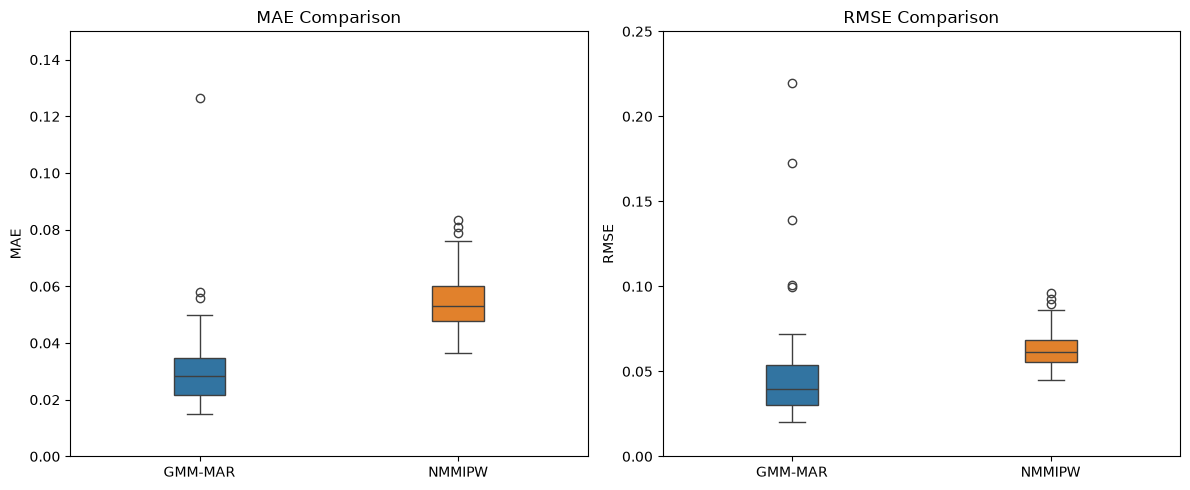

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left subplot: compare MAE
sns.boxplot(data=results[:, :2], ax=axes[0], width=0.2)
axes[0].set_title("MAE Comparison")
axes[0].set_xticks([0, 1], labels=["GMM-MAR", "NMMIPW"])
axes[0].set_ylabel("MAE")
axes[0].set_ylim(0, 0.15)

# Right subplot: compare RMSE
sns.boxplot(data=results[:, 2:4], ax=axes[1], width=0.2)
axes[1].set_title("RMSE Comparison")
axes[1].set_xticks([0, 1], labels=["GMM-MAR", "NMMIPW"])
axes[1].set_ylabel("RMSE")
axes[1].set_ylim(0, 0.25)

plt.tight_layout()
plt.show()

Below is part of the code for produing comparison conditional on the value of $X_1$.

In [7]:
# X1test = x1 * torch.ones(1000)
# X2test = pse._conditional(X1test)
# Xtest = torch.stack([X1test, X2test], dim=1)

In [8]:
# plt.scatter(X2test, psg, label='GMM-MAR')
# plt.scatter(X2test, psn, label='NMMIPW')
# plt.scatter(X2test, pst, label='Truth')
# plt.legend()
# plt.title(f'$X_1$ = {x1}')
# plt.ylabel('Estimated Propensity Score')
# plt.show()

$$
\mathbb P(M=0 \mid X=x) = \frac{p (X=x \mid M=0) \mathbb P(M=0)}{p(x)}
$$

- Estimate $p(X)$, $\mathbb P (M=\mathbf0)$ and $p(X \mid M=\mathbf0)$ on train data